In [17]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv('datasets/unsupervised/spotify-track-dataset.csv')

In [3]:
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

In [22]:
df.isnull().sum()

Unnamed: 0          0
track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [9]:
df_clean = df.dropna().drop_duplicates(subset='track_id').reset_index(drop=True)
print(f"Original shape: {df.shape} | Clean unique tracks: {df_clean.shape}")

Original shape: (114000, 21) | Clean unique tracks: (89740, 21)


In [23]:
df_clean.isnull().sum()

Unnamed: 0          0
track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [13]:
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [14]:
mood_features = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness',
    'valence', 'tempo', 'duration_ms'
]

In [15]:
X = df_clean[mood_features].copy()

In [18]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
# Step 2: Exploratory Data Analysis (EDA)

import matplotlib.pyplot as plt
import seaborn as sns

# Summary statistics for the selected audio features.
summary_stats = df_clean[mood_features].describe().T
summary_stats

# Correlation heatmap to inspect relationships between audio features.
corr = df_clean[mood_features].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Spotify Audio Feature Correlation Heatmap", fontsize=16)
plt.tight_layout()
plt.show()

In [20]:
df.shape

(114000, 21)

In [26]:
df['track_id']

0         5SuOikwiRyPMVoIQDJUgSV
1         4qPNDBW1i3p13qLCt0Ki3A
2         1iJBSr7s7jYXzM8EGcbK5b
3         6lfxq3CG4xtTiEg7opyCyx
4         5vjLSffimiIP26QG5WcN2K
                   ...          
113995    2C3TZjDRiAzdyViavDJ217
113996    1hIz5L4IB9hN3WRYPOCGPw
113997    6x8ZfSoqDjuNa5SVP5QjvX
113998    2e6sXL2bYv4bSz6VTdnfLs
113999    2hETkH7cOfqmz3LqZDHZf5
Name: track_id, Length: 114000, dtype: str

In [27]:
# PCA
from sklearn.decomposition import PCA
pca=PCA(n_components=10)
x_pca=pca.fit_transform(X_scaled)
x_pca

print("egenvalues")  # variance
print(pca.explained_variance_)
print("eigenvectors")   #directions
print(pca.components_)

egenvalues
[2.89072713 1.52163377 1.26302027 0.96292839 0.87236222 0.83662145
 0.73405369 0.45240139 0.32641926 0.13994385]
eigenvectors
[[ 0.2579717   0.50439613  0.51442168  0.09731218 -0.43257009 -0.28314839
   0.08364939  0.30002846  0.20141943 -0.0078639 ]
 [ 0.47317391 -0.27111493 -0.07733333  0.10162704  0.33101311 -0.3305692
  -0.13458755  0.49102528 -0.22355957 -0.39780708]
 [-0.21461006  0.05215412 -0.02974376  0.61145266  0.16010227 -0.15835089
   0.6944123  -0.09244372 -0.11053419 -0.15094234]
 [ 0.40137096  0.03807158 -0.04874301  0.25062486 -0.10077072  0.21252589
   0.02119323  0.04028691 -0.56801336  0.62628257]
 [ 0.26676322 -0.01517676 -0.19969146  0.54570801  0.0093141   0.45406325
  -0.20866244  0.07229688  0.57884042 -0.02915243]
 [-0.02510142 -0.19932086 -0.05742868 -0.10555893  0.30899468 -0.38850517
   0.17952432  0.23015222  0.45395246  0.63836865]
 [ 0.13068771  0.07837112 -0.16321301 -0.43286758 -0.01539753  0.49557389
   0.56885305  0.42546523  0.05209806 -0

In [30]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
x = pca.fit_transform(X_scaled)
y_sklearn = pca.transform(X_scaled)
y_sklearn

array([[ 0.68820333,  1.00862663],
       [-3.18210499,  1.30631133],
       [-1.31515149, -0.17021776],
       ...,
       [-0.99396006,  1.57770243],
       [-0.36963152, -0.0237288 ],
       [-0.89289634,  1.40011986]], shape=(89740, 2))

In [32]:
pc_columns = [f"PC{i}" for i in range(1, 11)]
x_pca_df = pd.DataFrame(x_pca, columns=pc_columns)

x_pca_df.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
0,0.688203,1.008627,0.600503,1.019096,-0.608603,-0.175985,0.260905,0.075946,-0.766931,-1.002879
1,-3.182105,1.306311,0.361626,-0.270880,-0.900826,-0.162762,-0.899366,-0.128536,-0.247136,0.220686
2,-1.315151,-0.170218,-0.081673,0.236185,-1.386438,-0.816058,-1.196721,0.371655,-0.568823,-0.498706
3,-3.186986,-0.240440,0.010935,-2.399009,0.651626,1.762749,-0.827227,0.388495,-0.533351,0.003274
4,-0.884286,0.302659,-0.459811,-0.312472,-0.238656,-0.068526,-0.977151,0.958055,0.054634,0.128050


In [39]:
df_clean[mood_features].dtypes

danceability        float64
energy              float64
loudness            float64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
duration_ms           int64
dtype: object

PCA retained 7 components (90.8% variance).


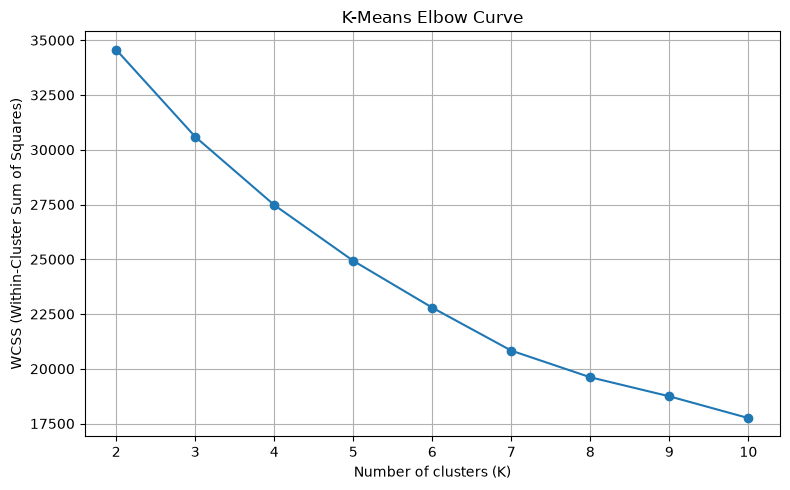

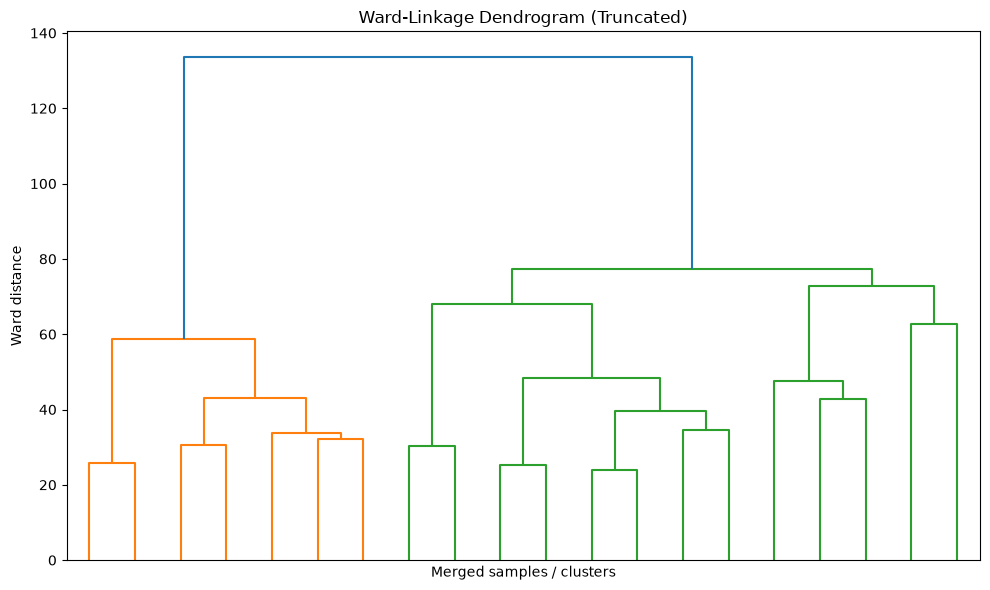

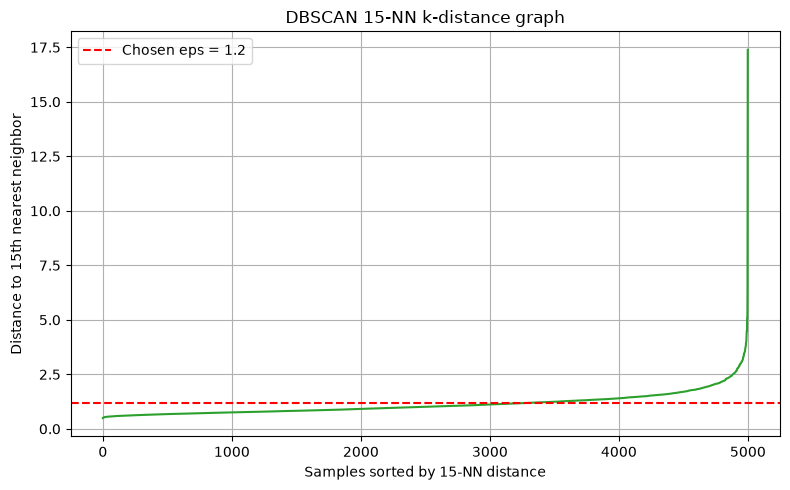

DBSCAN noise percentage: 16.02%


/var/folders/7b/5_gy8f1j7171y56xbfvy4r7h0000gn/T/ipykernel_92597/3273589469.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


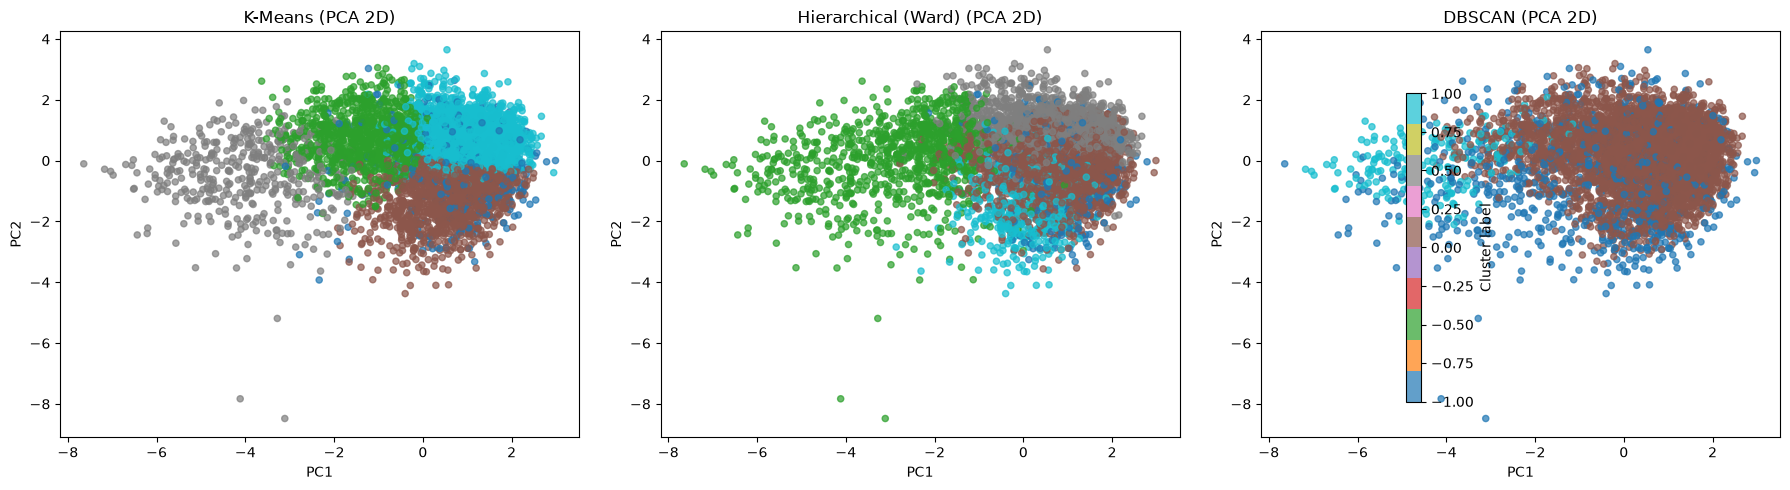

In [42]:
# Step 4: Clustering Evaluation & Comparison

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram

# ----------------------------
# 1. Reproducible 5,000-row sample
# ----------------------------
if len(df_clean) < 5000:
    raise ValueError(f"Need at least 5,000 cleaned tracks; found {len(df_clean)}.")

sample_df = df_clean.sample(n=5000, random_state=42).reset_index(drop=True)
sample_scaled = scaler.transform(sample_df[mood_features])

# Fit PCA on the full standardized dataset, then transform the sample into
# the same reduced feature space used for clustering.
pca_cluster = PCA(n_components=0.85, random_state=42)
X_pca = pca_cluster.fit_transform(X_scaled)
sample_X = pca_cluster.transform(sample_scaled)

print(
    f"PCA retained {pca_cluster.n_components_} components "
    f"({pca_cluster.explained_variance_ratio_.sum():.1%} variance)."
)

# ----------------------------
# 2. K-Means: Elbow curve
# ----------------------------
inertia_scores = []
k_values = range(2, 11)

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(sample_X)
    inertia_scores.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_scores, marker='o', color='tab:blue')
plt.xlabel("Number of clusters (K)")
plt.ylabel("WCSS (Within-Cluster Sum of Squares)")
plt.title("K-Means Elbow Curve")
plt.grid(True)
plt.tight_layout()
plt.show()

kmeans_model = KMeans(n_clusters=5, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(sample_X)

# ----------------------------
# 3. Hierarchical clustering: Ward-linkage dendrogram
# ----------------------------
ward_linkage = linkage(sample_X, method='ward')

plt.figure(figsize=(10, 6))
dendrogram(
    ward_linkage,
    truncate_mode='lastp',
    p=20,
    leaf_rotation=90,
    show_leaf_counts=True,
    no_labels=True
)
plt.title("Ward-Linkage Dendrogram (Truncated)")
plt.xlabel("Merged samples / clusters")
plt.ylabel("Ward distance")
plt.tight_layout()
plt.show()

agg_model = AgglomerativeClustering(n_clusters=5, linkage='ward')
agg_labels = agg_model.fit_predict(sample_X)

# ----------------------------
# 4. DBSCAN: 15-nearest-neighbor k-distance graph
# ----------------------------
nn = NearestNeighbors(n_neighbors=15)
nn.fit(sample_X)
distances, _ = nn.kneighbors(sample_X)
k_distance = np.sort(distances[:, -1])

dbscan_eps = 1.2
plt.figure(figsize=(8, 5))
plt.plot(k_distance, color='tab:green')
plt.axhline(dbscan_eps, color='red', linestyle='--', label=f'Chosen eps = {dbscan_eps}')
plt.title("DBSCAN 15-NN k-distance graph")
plt.xlabel("Samples sorted by 15-NN distance")
plt.ylabel("Distance to 15th nearest neighbor")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

dbscan_model = DBSCAN(eps=dbscan_eps, min_samples=15)
dbscan_labels = dbscan_model.fit_predict(sample_X)
noise_pct = np.mean(dbscan_labels == -1) * 100
print(f"DBSCAN noise percentage: {noise_pct:.2f}%")

# ----------------------------
# 5. Cluster quality metrics
# ----------------------------
def cluster_metrics(X, labels, ignore_noise=False):
    """Return cluster count and quality scores; omit DBSCAN noise from scores."""
    labels = np.asarray(labels)
    valid = labels != -1 if ignore_noise else np.ones(labels.shape, dtype=bool)
    X_valid = X[valid]
    labels_valid = labels[valid]
    n_clusters = len(np.unique(labels_valid))

    if n_clusters < 2 or n_clusters >= len(labels_valid):
        return n_clusters, np.nan, np.nan

    try:
        silhouette = silhouette_score(X_valid, labels_valid)
        davies_bouldin = davies_bouldin_score(X_valid, labels_valid)
    except ValueError:
        silhouette, davies_bouldin = np.nan, np.nan

    return n_clusters, silhouette, davies_bouldin

comparison_rows = []
for model_name, labels, ignore_noise in [
    ("K-Means", kmeans_labels, False),
    ("Hierarchical (Ward)", agg_labels, False),
    ("DBSCAN", dbscan_labels, True),
]:
    n_clusters, silhouette, davies_bouldin = cluster_metrics(
        sample_X, labels, ignore_noise=ignore_noise
    )
    comparison_rows.append({
        "Model": model_name,
        "Clusters Found": n_clusters,
        "Silhouette Score": silhouette,
        "Davies-Bouldin Index": davies_bouldin,
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df

# ----------------------------
# 6. 3-panel 2D PCA scatterplot
# ----------------------------
# The clustering inputs are PCA-transformed; plot their first two components.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, labels, title in zip(
    axes,
    [kmeans_labels, agg_labels, dbscan_labels],
    ["K-Means", "Hierarchical (Ward)", "DBSCAN"],
):
    points = ax.scatter(
        sample_X[:, 0], sample_X[:, 1],
        c=labels, cmap='tab10', s=20, alpha=0.7
    )
    ax.set_title(f"{title} (PCA 2D)")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

fig.colorbar(points, ax=axes, label="Cluster label", shrink=0.8)
plt.tight_layout()
plt.show()